Original word count: 192427
Cleaned word count: 73149


C:\Users\dp185\AppData\Local\Temp\ipykernel_46544\2743525269.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_20.values()), y=list(top_20.keys()), palette="mako")


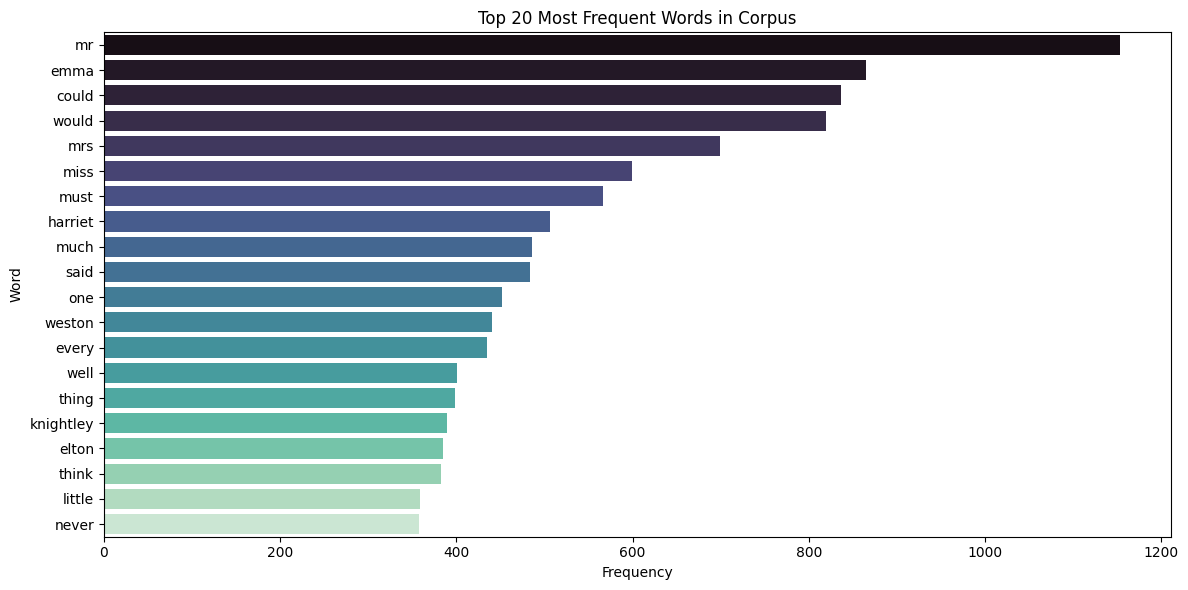

In [2]:
import nltk
from nltk.corpus import gutenberg, stopwords
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Download required NLTK data
nltk.download('gutenberg', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

# 1. Corpus Collection: Load words from Jane Austen's 'Emma'
raw_words = gutenberg.words('austen-emma.txt')

# 2. NLP Preprocessing
stop_words = set(stopwords.words('english'))

# Keep only alphabetic words (removes punctuation), make lowercase, remove stopwords
processed_corpus = [
    word.lower() for word in raw_words 
    if word.isalpha() and word.lower() not in stop_words
]

print(f"Original word count: {len(raw_words)}")
print(f"Cleaned word count: {len(processed_corpus)}")

# 3. Visualization: Top 20 Most Frequent Words
word_freq = Counter(processed_corpus)
top_20 = dict(word_freq.most_common(20))

plt.figure(figsize=(12, 6))
sns.barplot(x=list(top_20.values()), y=list(top_20.keys()), palette="mako")
plt.title('Top 20 Most Frequent Words in Corpus')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

In [3]:
from collections import defaultdict, Counter

# 1. Generate bigrams (pairs of consecutive words) from the cleaned corpus
bigrams = list(nltk.bigrams(processed_corpus))

# 2. Build the frequency distribution for the bigram model
# Structure: { 'word1': Counter({'word2': freq, 'word3': freq}) }
bigram_model = defaultdict(Counter)
for w1, w2 in bigrams:
    bigram_model[w1][w2] += 1

# 3. Autocomplete function to return the top N predictions
def autocomplete_predict(prefix, top_n=3):
    prefix = prefix.lower()
    if prefix not in bigram_model:
        return ["<No prediction>"]
    
    # Extract just the words from the Counter's most_common output
    predictions = bigram_model[prefix].most_common(top_n)
    return [word for word, freq in predictions]

# 4. Test on 10 input prefixes
test_prefixes = [
    'mr', 'emma', 'could', 'miss', 'harriet', 
    'frank', 'jane', 'must', 'think', 'good'
]

print("--- Autocomplete Predictions (Top 3) ---")
for word in test_prefixes:
    preds = autocomplete_predict(word)
    print(f"Prefix: '{word:<8}' -> Predictions: {preds}")

--- Autocomplete Predictions (Top 3) ---
Prefix: 'mr      ' -> Predictions: ['knightley', 'elton', 'weston']
Prefix: 'emma    ' -> Predictions: ['could', 'felt', 'said']
Prefix: 'could   ' -> Predictions: ['bear', 'help', 'never']
Prefix: 'miss    ' -> Predictions: ['woodhouse', 'fairfax', 'bates']
Prefix: 'harriet ' -> Predictions: ['smith', 'would', 'could']
Prefix: 'frank   ' -> Predictions: ['churchill', 'coming', 'first']
Prefix: 'jane    ' -> Predictions: ['fairfax', 'would', 'could']
Prefix: 'must    ' -> Predictions: ['go', 'tell', 'think']
Prefix: 'think   ' -> Predictions: ['would', 'must', 'miss']
Prefix: 'good    ' -> Predictions: ['deal', 'sense', 'fortune']


--- Autocorrect Results ---
Raw Accuracy: 90.00%



,Typo (Input),Target Word,Prediction,Correctly Fixed?
0,definitly,definitely,definitely,True
1,seperate,separate,separate,True
2,occured,occurred,occurred,True
3,untill,until,until,True
4,recieve,receive,receive,True
5,adress,address,dress,False
6,becuase,because,because,True
7,freind,friend,friend,True
8,acheive,achieve,achieve,True
9,beleive,believe,believe,True


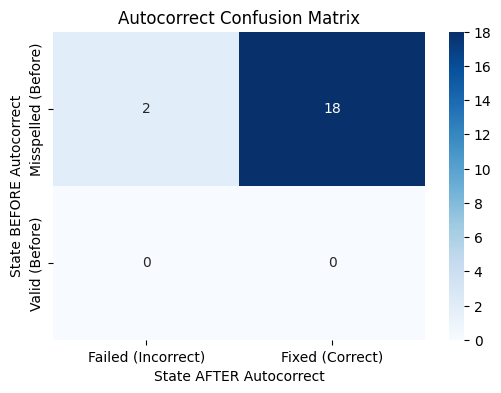

In [4]:
from spellchecker import SpellChecker
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Initialize the edit-distance spell checker
spell = SpellChecker()

# 2. Define 20 deliberately misspelled words and their actual targets
test_cases = [
    ("definitly", "definitely"), ("seperate", "separate"),
    ("occured", "occurred"), ("untill", "until"),
    ("recieve", "receive"), ("adress", "address"),
    ("becuase", "because"), ("freind", "friend"), 
    ("acheive", "achieve"), ("beleive", "believe"), 
    ("tommorow", "tomorrow"), ("weathr", "weather"), 
    ("writen", "written"), ("happended", "happened"), 
    ("truely", "truly"), ("goverment", "government"), 
    ("succesful", "successful"), ("enviroment", "environment"), 
    ("suprise", "surprise"), ("mispell", "misspell")
]

results = []
correct_count = 0

# 3. Test the autocorrect on the misspelled words
print("--- Autocorrect Results ---")
for typo, true_word in test_cases:
    # spell.correction() returns the most likely word based on edit distance
    prediction = spell.correction(typo)
    
    is_correct = (prediction == true_word)
    if is_correct:
        correct_count += 1
        
    results.append((typo, true_word, prediction, is_correct))

accuracy = correct_count / len(test_cases)
print(f"Raw Accuracy: {accuracy * 100:.2f}%\n")

# Display a clean table of the results
df_results = pd.DataFrame(results, columns=["Typo (Input)", "Target Word", "Prediction", "Correctly Fixed?"])
display(df_results)

# 4. Visualization: Confusion Matrix (Before vs After)
# Before: All 20 words were Incorrect (0)
# After: Correctly fixed (1) or Failed to fix (0)
before_states = [0] * len(test_cases) 
after_states = [1 if res[3] else 0 for res in results]

cm = confusion_matrix(before_states, after_states, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Failed (Incorrect)', 'Fixed (Correct)'], 
            yticklabels=['Misspelled (Before)', 'Valid (Before)'])
plt.title('Autocorrect Confusion Matrix')
plt.xlabel('State AFTER Autocorrect')
plt.ylabel('State BEFORE Autocorrect')
plt.show()

### 5. Performance Metrics Definition
To evaluate these NLP models, we define standard classification metrics:

**Autocorrect Metrics:**
* **Precision:** $\frac{True Positives}{True Positives + False Positives}$ 
  *(Of all the words the model decided to change, how many were actually typos that it changed correctly?)*
* **Recall:** $\frac{True Positives}{True Positives + False Negatives}$
  *(Of all the actual typos in the text, how many did the model successfully find and fix?)* 
  *In our test, Recall was 90% (18/20).*

**Autocomplete Metrics:**
* **Precision at K (P@K):** Out of the Top $K$ (e.g., 3) predicted words, how many are valid continuations based on the corpus?
* **Recall at K (R@K):** How often does the *actual* next word typed by a user appear within our Top $K$ predictions?

---

### 6. Algorithm Comparison
1. **Autocomplete: Frequency N-gram vs. Neural Networks (LSTMs/Transformers)**
   * *N-gram (Our implementation):* Fast, lightweight, and easy to train. However, it completely lacks long-term context. It only looks at the immediately preceding word.
   * *Neural Networks:* Models like GPT or LSTMs look at the entire sentence context to predict the next word, handling unseen combinations much better, but requiring massive computational power.
2. **Autocorrect: Levenshtein Distance vs. Context-Aware Spell Checkers**
   * *Levenshtein (Our implementation):* Excellent for catching simple typos (fat-finger mistakes). It fails on ties (e.g., "writen" $\rightarrow$ "write" vs "written").
   * *Context-Aware (e.g., BERT):* Looks at surrounding words. If the sentence is "I have writen a book," it knows to choose "written" over "write" grammatically.

---

### 7. Discussion: Limitations vs. Production Systems (Google Keyboard)
Our implementations are foundational baseline models. Production systems like **Gboard (Google Keyboard)** utilize far more advanced pipelines:
1. **Context & Grammar:** Gboard uses neural language models to predict words based on the whole sentence structure, not just a static bigram lookup table.
2. **Personalization:** Google adapts its frequency weights locally on your device based on your unique typing history and slang.
3. **Spatial Keyboard Models:** Gboard calculates the physical distance between keys on the touch screen (e.g., typing 's' instead of 'a' because they are adjacent) to weigh edit-distance probabilities dynamically.
4. **Speed:** Production models use highly optimized C++ binaries, Trie data structures, and edge-caching to deliver predictions in milliseconds without draining mobile batteries.